# 06 · Generative stress testing: bootstrap, FHS, Diffusion-FHS and TimeGAN

**Who this is for:** risk managers and allocators. A Calmar ratio or a maximum drawdown measured on one short history is a *single draw*: two or three years contain one or two drawdown episodes. Generative models trained on the **joint** daily returns of the strategy and its risk factors produce thousands of plausible histories, and with them a *distribution* of path risk.

Four generators are compared on one fidelity battery:

| Generator | What it keeps | What it cannot do |
|---|---|---|
| Stationary block bootstrap | the empirical days, short-range dependence | create a day it has not seen; volatility regimes longer than the block |
| FHS (GJR-GARCH-t + joint residuals) | volatility clustering and leverage (model); joint shock shapes (data) | create a new *combination* of shocks |
| **Diffusion-FHS** (GJR-GARCH-t + conditional DDPM innovations) | as FHS, plus the regime-dependent joint law of shocks, learned rather than replayed | extrapolate far beyond the support of the data (by design, bounded) |
| TimeGAN | in principle, everything | in practice, stable training on ~1,000 noisy days |

Drift is **not** learned, because it cannot be learned from a few years of data. Paths are zero-mean and the strategy's drift is set explicitly: to zero (pure risk), to the in-sample Sharpe, or drawn from a Bayesian posterior.

The models are trained here on the open dataset (never-seen period) only, so the notebook runs from shipped data. The paper pools it with the development sample. The diffusion parts need JAX (`pip install "fmflow[gen]"`).

In [1]:
# fmflow-setup: runs as-is everywhere. In an installed environment it only locates the repository; on Google Colab,
# Binder or a Jupyter without the package, it downloads the repository once and installs it (about a minute).
import importlib, importlib.util, os, shutil, subprocess, sys
from pathlib import Path

REPO_URL = os.environ.get("FMFLOW_REPO_URL", "https://github.com/bahakh19/first-mover-flow")   # set it to use a fork


def _run(cmd: list, what: str, hint: str = "") -> None:
    r = subprocess.run(cmd, capture_output=True, text=True)
    if r.returncode:
        raise RuntimeError(f"{what} failed:\n{(r.stderr or r.stdout).strip()[-1500:]}\n{hint}")


_here = Path.cwd()
_root = next((p for p in (_here, *_here.parents, _here / "first-mover-flow") if (p / "src" / "fmflow").is_dir()), None)
if _root is None:                                                  # notebooks need the repository's data/ folder
    _root = (_here / "first-mover-flow").resolve()
    print(f"Downloading {REPO_URL} ...")
    if shutil.which("git"):
        _run(["git", "clone", "-q", "--depth", "1", REPO_URL, str(_root)], f"git clone {REPO_URL}",
             "Is the repository public? For a fork or a local copy, set the environment variable FMFLOW_REPO_URL.")
    else:                                                          # no git: the GitHub zip archive of the main branch
        import io, urllib.request, zipfile
        with urllib.request.urlopen(REPO_URL.rstrip("/") + "/archive/refs/heads/main.zip") as _r:
            zipfile.ZipFile(io.BytesIO(_r.read())).extractall(_here)
        (_here / (REPO_URL.rstrip("/").split("/")[-1] + "-main")).rename(_root)
if importlib.util.find_spec("fmflow") is None:
    print("Installing fmflow and its dependencies (about a minute) ...")
    _target = f"{_root}[plot,gen]"
    if importlib.util.find_spec("pip"):
        _run([sys.executable, "-m", "pip", "install", "-q", "-e", _target], "pip install")
    elif shutil.which("uv"):                                       # uv-created environments have no pip
        _run(["uv", "pip", "install", "-q", "--python", sys.executable, "-e", _target], "uv pip install")
    else:
        raise RuntimeError("this kernel has neither pip nor uv: install the package from a terminal (INSTALL.md)")
    sys.path.insert(0, str(_root / "src"))
    importlib.invalidate_caches()
os.chdir(_root / "notebooks")
print("fmflow", importlib.import_module("fmflow").__version__, "| repository:", _root)

fmflow 2.2.4 | repository: /home/claude/work/v22/repo


In [2]:
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from fmflow import StrategyConfig, load_prices, load_ratings, run_strategy
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
pd.set_option("display.float_format", "{:.3f}".format)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3})
BLUE, ORANGE, GREEN, RED, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#e34948", "#9a9a9a"
P = load_prices(ROOT / "data/open/MarketData_Normalized.csv")
R = load_ratings(ROOT / "data/open/Ratings_Normalized.csv", P)
SIG = pd.read_csv(ROOT / "tests/fixtures/open_sig_gjr.csv.gz", index_col=0, parse_dates=True)   # cached GARCH forecasts
EV = slice("2024-01-05", "2026-08-05")                                                          # pre-registered window
CFG = StrategyConfig.fmf_n_scalable()                                                           # leg fraction 0.4
out = run_strategy(P, R, CFG, sig_vol=SIG)
print(f"{out.prices.shape[1]} stocks, {len(out.prices)} sessions, {len(out.ratings):,} accepted ratings")
from fmflow.benchmarks import comparable_books
from fmflow.generative.baselines import block_bootstrap_paths, fhs_paths
from fmflow.generative import jax_status
JAX_OK, JAX_MSG = jax_status()          # JAX can be installed yet unusable (e.g. a CPU without AVX)
print("JAX:", JAX_MSG)
if JAX_OK:
    from fmflow.generative.diffusion_fhs import DiffusionFHS
    from fmflow.generative.timegan import TimeGAN
from fmflow.generative.windows import make_windows, stitch
from fmflow.generative import fidelity as F, stress as S
mom = comparable_books(out, include_allocations=False)["12-1 momentum (Jegadeesh-Titman)"]
frame = pd.DataFrame({"FMF": out.net_returns, "MKT": out.returns.mean(axis=1), "MOM": mom}).loc[EV].dropna()
std = (frame - frame.mean()) / frame.std()
REAL = np.stack([std.to_numpy()[i:i + 32] for i in range(len(std) - 32)])
print(frame.corr().round(2)); print(f"{len(frame)} days")

30 stocks, 899 sessions, 2,363 accepted ratings


JAX: jax 0.12.0.1 on cpu


       FMF    MKT   MOM
FMF  1.000 -0.090 0.610
MKT -0.090  1.000 0.270
MOM  0.610  0.270 1.000
647 days


## 1. Train the generators

Diffusion-FHS trains its conditional denoiser with a chronological validation split and early stopping. On this little data an unregularised network memorises its training days, and memorisation shows up as under-dispersed draws.

best validation step: 200


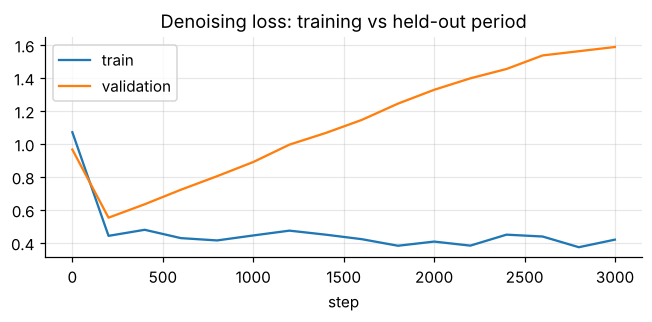

In [3]:
NP, HZ = 600, 640
paths = {"block bootstrap": block_bootstrap_paths(std, NP, HZ, 21, 1), "FHS": fhs_paths(std, NP, HZ, 1)}
if JAX_OK:
    dfhs = DiffusionFHS(["FMF", "MKT", "MOM"], T=100, hidden=128, n_blocks=3, seed=0).fit([frame], steps=3000)
    print("best validation step:", dfhs.model.best_step)
    h = pd.DataFrame(dfhs.model.history, columns=["step", "train", "validation"]).set_index("step")
    h.plot(figsize=(7, 2.6), title="Denoising loss: training vs held-out period"); plt.show()
    tg = TimeGAN(24, 3, hidden=24, seed=0).fit(make_windows([frame], 24).X, steps=(800, 800, 1000))
    paths["Diffusion-FHS"] = dfhs.simulate(NP, HZ, seed=1, units="standardised", steps=50)
    G = stitch(tg.sample(3000), NP, HZ, np.random.default_rng(0))
    paths["TimeGAN"] = (G - G.mean((0, 1))) / G.std((0, 1))
else:
    print("Diffusion-FHS and TimeGAN skipped:", JAX_MSG, "-- the rest of the notebook runs with bootstrap and FHS.")

## 2. Fidelity

The battery checks:
- **stylised facts**: fat tails, volatility clustering, cross-correlation, tail dependence;
- the **discriminative score**: a gradient-boosting classifier tries to tell real 32-day windows from synthetic ones (real windows are split chronologically so overlapping twins cannot leak), and 0 means indistinguishable;
- the **memorisation ratio**: distance of each synthetic window to its nearest training window, relative to held-out real windows, where values well below 1 mean copying.

In [4]:
rows = {}
for k, Pp in paths.items():
    W = Pp[:, : (HZ // 32) * 32].reshape(-1, 32, 3)
    sf = F.stylised_facts(W, ["FMF", "MKT", "MOM"])
    rows[k] = {**sf[["FMF ex.kurt", "MKT ex.kurt", "MKT acf|r| 1-10", "corr FMF-MKT", "corr FMF-MOM", "tail dep FMF|MOM (5%)"]].to_dict(),
               "discriminative": F.discriminative_score(REAL, W[:2000]),
               "memorisation": F.memorisation_ratio(REAL[:400], REAL[450:], W[:2000])}
sf = F.stylised_facts(REAL, ["FMF", "MKT", "MOM"])
rows["REAL"] = {k: sf[k] for k in rows["FHS"] if k in sf.index}
display(pd.DataFrame(rows).T)

,FMF ex.kurt,MKT ex.kurt,MKT acf|r| 1-10,corr FMF-MKT,corr FMF-MOM,tail dep FMF|MOM (5%),discriminative,memorisation
block bootstrap,4.177,11.984,-0.008,-0.098,0.603,0.581,0.166,0.706
FHS,3.988,7.094,-0.006,-0.141,0.491,0.322,0.022,0.814
Diffusion-FHS,4.943,10.322,-0.002,-0.118,0.424,0.293,0.027,0.795
TimeGAN,-0.596,-0.196,-0.003,0.966,0.999,0.955,0.500,0.850
REAL,4.418,12.251,-0.005,-0.109,0.585,0.498,NaN,NaN


## 3. Path risk: the distribution of drawdown and Calmar ratio

Each generator's FMF channel is scaled to the strategy's volatility. The drift is set to zero, to the realised Sharpe ratio, or to a Bayesian posterior draw from a sceptical prior (notebook 05).

In [5]:
from fmflow.analytics.bayes import bayesian_sharpe
sd = frame["FMF"].std()
post = bayesian_sharpe(frame["FMF"], prior_sr_sd=1.0, n_draws=20000).draws
rng = np.random.default_rng(0)
res = {}
for k, Pp in paths.items():
    for dn, sr in (("zero drift", np.zeros(NP)), ("realised SR", np.full(NP, frame["FMF"].mean() / sd * 252 ** 0.5)),
                   ("posterior SR (sceptical)", rng.choice(post, NP))):
        st = S.path_stats((Pp[:, :, 0] * sd + (sr * sd / 252 ** 0.5)[:, None])[:, :, None])
        res[(k, dn)] = {"median MaxDD": st["MaxDD"].median(), "5% MaxDD": st["MaxDD"].quantile(.05),
                        "median Calmar": st["Calmar"].median(), "P(Calmar > 0.5)": (st["Calmar"] > .5).mean(),
                        "P(loss over horizon)": (st["total return"] < 0).mean()}
display(pd.DataFrame(res).T)

median MaxDD  5% MaxDD  \
block bootstrap zero drift                      -0.160    -0.265   
                realised SR                     -0.087    -0.139   
                posterior SR (sceptical)        -0.098    -0.225   
FHS             zero drift                      -0.159    -0.317   
                realised SR                     -0.100    -0.214   
                posterior SR (sceptical)        -0.114    -0.266   
Diffusion-FHS   zero drift                      -0.145    -0.361   
                realised SR                     -0.097    -0.256   
                posterior SR (sceptical)        -0.111    -0.277   
TimeGAN         zero drift                      -0.267    -0.454   
                realised SR                     -0.197    -0.345   
                posterior SR (sceptical)        -0.213    -0.388   

                                          median Calmar  P(Calmar > 0.5)  \
block bootstrap zero drift                       -0.121            0.120   
                realised SR                       1.047            0.780   
                posterior SR (sceptical)          0.639            0.570   
FHS             zero drift                       -0.063            0.162   
                realised SR                       1.001            0.717   
                posterior SR (sceptical)          0.580            0.528   
Diffusion-FHS   zero drift                        0.052            0.202   
                realised SR                       1.240            0.747   
                posterior SR (sceptical)          0.673            0.563   
TimeGAN         zero drift                       -0.025            0.187   
                realised SR                       0.510            0.505   
                posterior SR (sceptical)          0.379            0.415   

                                          P(loss over horizon)  
block bootstrap zero drift                               0.632  
                realised SR                              0.035  
                posterior SR (sceptical)                 0.195  
FHS             zero drift                               0.567  
                realised SR                              0.072  
                posterior SR (sceptical)                 0.200  
Diffusion-FHS   zero drift                               0.460  
                realised SR                              0.087  
                posterior SR (sceptical)                 0.197  
TimeGAN         zero drift                               0.527  
                realised SR                              0.198  
                posterior SR (sceptical)                 0.277

## 4. Conditional stress: what happens to FMF when momentum crashes?

FMF-N is correlated with momentum, so a momentum crash is its natural stress scenario. Among the simulated 63-day windows, select those where the momentum book has its worst 2% and look at FMF's return in the same windows.

In [6]:
sdv = frame.std().to_numpy()
tab = {}
for k in [g for g in ("block bootstrap", "FHS", "Diffusion-FHS") if g in paths]:
    W = paths[k][:, : (HZ // 63) * 63].reshape(-1, 63, 3) * sdv
    cum = np.cumprod(1 + W, axis=1)[:, -1] - 1
    crash = cum[:, 2] <= np.quantile(cum[:, 2], 0.02)
    mk = cum[:, 1] <= np.quantile(cum[:, 1], 0.02)
    tab[k] = {"FMF mean | momentum crash": cum[crash, 0].mean(), "FMF 5% | momentum crash": np.quantile(cum[crash, 0], .05),
              "FMF mean | market crash": cum[mk, 0].mean(), "FMF 5% | all windows": np.quantile(cum[:, 0], .05)}
display(pd.DataFrame(tab).T)

,FMF mean | momentum crash,FMF 5% | momentum crash,FMF mean | market crash,FMF 5% | all windows
block bootstrap,-0.052,-0.089,0.008,-0.065
FHS,-0.063,-0.140,0.015,-0.079
Diffusion-FHS,-0.055,-0.115,-0.029,-0.082


## 5. Reading the results honestly

- Generators do **not** create information about the *mean*. They quantify **path risk** given the dependence structure they learned. That is why drift is an explicit input, and why the zero-drift rows matter most to a risk manager.
- **Data size decides which generator to trust.** Trained on these 647 days alone, the diffusion denoiser stops early (best validation step 200) and *under-fits* the dependence: its correlation with momentum is 0.42 against 0.59 in the data, and its 5% tail dependence 0.29 against 0.50. FHS shows a milder version of the same bias. The bootstrap keeps the dependence but only re-orders history (its memorisation ratio of 0.71 is copying by construction). On the pooled development and never-seen samples used in the paper (about 1,900 days), Diffusion-FHS reproduces the momentum correlation (0.62 against 0.66) with the lowest discriminative score of the four generators. Rule of thumb: below roughly 1,000 days, report the bootstrap and FHS; above it, add Diffusion-FHS.
- **Momentum crashes are the stress, under every generator.** In the worst 2% of momentum windows, the 5% quantile of FMF's three-month return is −9% to −14%, against −7% to −8% unconditionally. With this little data, the market-crash rows are close to zero and differ in sign across generators, so they should not be read as a hedge.
- TimeGAN's failure modes (draws nearly collinear across channels, Gaussian-looking marginals, a classifier that separates them perfectly) are documented, not hidden. On this little data it is not a reliable stress engine.
- The paper pools both samples and simulates 1,000 five-year paths (`fmflow stress`, Block 17.6 of the research notebook).